**PÓS-GRADUAÇÃO · DATA SCIENCE & BIG DATA APLICADOS NA INDÚSTRIA**

# Aula 05 · Exercício 01
## Agrupamento de viagens

| Identificação | Dados |
| :--- | :--- |
| **Aluno** | Carlos Alexandre Duarte Pereira |
| **Curso** | Data Science & Big Data Aplicados na Indústria |
| **Disciplina** | Data Science e Big Data |
| **Professor** | Me. Daniel Vieira |
| **Data** | 31/10/2026 |

---

**Tema:** aprendizado não supervisionado com K-Means.

Análise de 12 viagens a partir da distância percorrida (km) e do tempo de deslocamento (horas).


In [1]:
# 1. IMPORTAÇÃO DAS BIBLIOTECAS
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from IPython.display import display

In [2]:
# 2. CRIAÇÃO DO CONJUNTO DE DADOS
# Dados do exercício 1
dados = {
    "viagem": ["V01", "V02", "V03", "V04", "V05", "V06",
               "V07", "V08", "V09", "V10", "V11", "V12"],
    "distancia": [15, 20, 18, 25, 150, 180, 160, 200, 650, 700, 680, 750],
    "tempo": [0.5, 0.7, 0.6, 0.8, 2.5, 3.0, 2.8, 3.5, 9.0, 10.0, 9.5, 11.0]
}
df = pd.DataFrame(dados)

In [3]:
df.head(12)

,viagem,distancia,tempo
0,V01,15,0.5
1,V02,20,0.7
2,V03,18,0.6
3,V04,25,0.8
4,V05,150,2.5
5,V06,180,3.0
6,V07,160,2.8
7,V08,200,3.5
8,V09,650,9.0
9,V10,700,10.0


In [4]:
# 3. SELEÇÃO E PADRONIZAÇÃO DOS DADOS
# Padronização de distância e tempo, que possuem escalas diferentes.
scaler = StandardScaler()
X = scaler.fit_transform(df[["distancia", "tempo"]])
print("Dados padronizados:")
display(pd.DataFrame(X, columns=["distancia_padronizada", "tempo_padronizado"],
                     index=df["viagem"]).round(4))

Dados padronizados:


,distancia_padronizada,tempo_padronizado
viagem,,
V01,-0.9672,-1.0106
V02,-0.9500,-0.9599
V03,-0.9569,-0.9852
V04,-0.9328,-0.9346
V05,-0.5020,-0.5042
V06,-0.3986,-0.3776
V07,-0.4675,-0.4283
V08,-0.3297,-0.2511
V09,1.2211,1.1414


In [5]:
# 4. CRIAÇÃO, TREINAMENTO E IDENTIFICAÇÃO DOS GRUPOS
modelo = KMeans(
    n_clusters=3,     # Quantidade de grupos solicitada
    random_state=42,  # Permite reproduzir os resultados
    n_init=10         # Testa 10 inicializações
)
df["grupo"] = modelo.fit_predict(X)
# Os números dos grupos são rótulos, sem ordem de qualidade ou grandeza.
print("Resultado dos agrupamentos:")
display(df.sort_values(["grupo", "distancia"]))

# Médias e viagens de cada grupo
resumo = df.groupby("grupo").agg(
    viagens=("viagem", lambda valores: ", ".join(valores)),
    quantidade=("viagem", "count"),
    distancia_media_km=("distancia", "mean"),
    tempo_medio_h=("tempo", "mean")
)
print("\nResumo por grupo:")
display(resumo.round(3))

Resultado dos agrupamentos:


,viagem,distancia,tempo,grupo
4,V05,150,2.5,0
6,V07,160,2.8,0
5,V06,180,3.0,0
7,V08,200,3.5,0
8,V09,650,9.0,1
10,V11,680,9.5,1
9,V10,700,10.0,1
11,V12,750,11.0,1
0,V01,15,0.5,2
2,V03,18,0.6,2



Resumo por grupo:


,viagens,quantidade,distancia_media_km,tempo_medio_h
grupo,,,,
0,"V05, V06, V07, V08",4,172.5,2.950
1,"V09, V10, V11, V12",4,695.0,9.875
2,"V01, V02, V03, V04",4,19.5,0.650


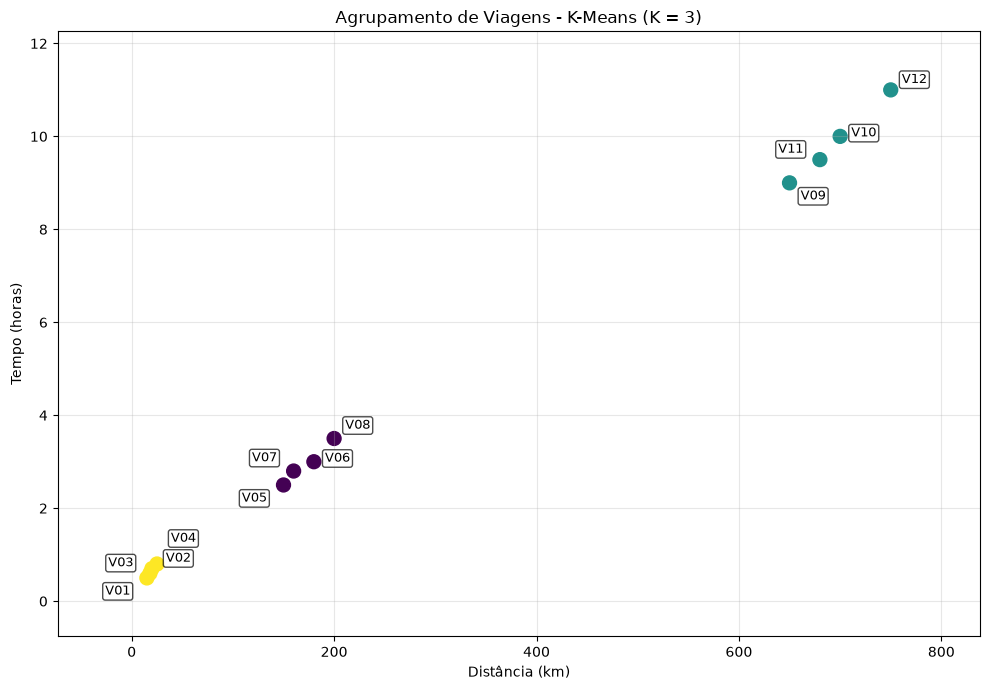

In [6]:
# 5. VISUALIZAÇÃO DOS AGRUPAMENTOS
plt.figure(figsize=(10, 7))
plt.scatter(df["distancia"], df["tempo"],
            c=df["grupo"], cmap="viridis", s=100)

# Deslocamentos em pontos para separar os nomes das viagens próximas.
deslocamentos = {
    "V01": (-30, -12), "V02": (10, 5), "V03": (-30, 5), "V04": (10, 16),
    "V05": (-30, -12), "V06": (8, 0), "V07": (-30, 7), "V08": (8, 7),
    "V09": (8, -12), "V10": (8, 0), "V11": (-30, 5), "V12": (8, 5)
}
for i in range(len(df)):
    viagem = df.loc[i, "viagem"]
    plt.annotate(viagem, (df.loc[i, "distancia"], df.loc[i, "tempo"]),
                 xytext=deslocamentos[viagem], textcoords="offset points",
                 fontsize=9,
                 bbox=dict(boxstyle="round,pad=0.2", fc="white", alpha=0.7))
plt.xlabel("Distância (km)")
plt.ylabel("Tempo (horas)")
plt.title("Agrupamento de Viagens - K-Means (K = 3)")
plt.margins(x=0.12, y=0.12)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

,K,inercia_WCSS
0,1,24.0000
1,2,1.4926
2,3,0.2585
3,4,0.1024
4,5,0.0648
5,6,0.0279
6,7,0.0177
7,8,0.0073


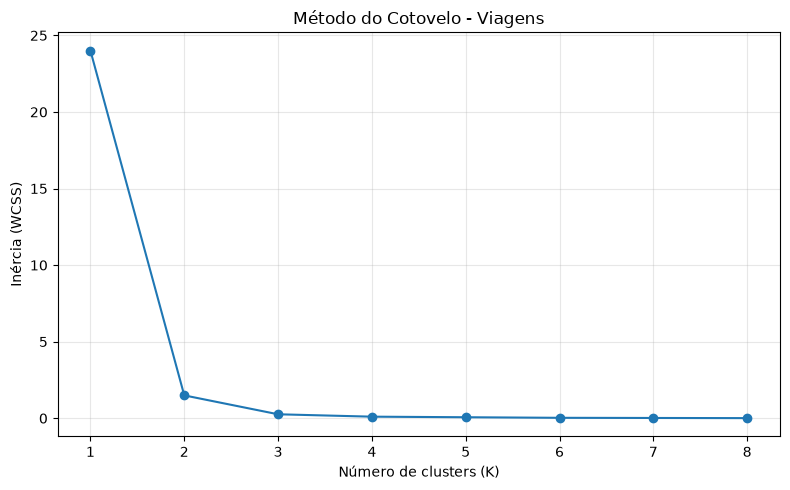

Redução da inércia de K=2 para K=3: 82.68%


In [7]:
# 6. MÉTODO DO COTOVELO
# Teste de K entre 1 e 8 com os dados padronizados
inercias = []
valores_k = range(1, 9)
for k in valores_k:
    modelo_k = KMeans(n_clusters=k, random_state=42, n_init=10)
    modelo_k.fit(X)
    inercias.append(modelo_k.inertia_)

display(pd.DataFrame({"K": list(valores_k), "inercia_WCSS": inercias}).round(4))

plt.figure(figsize=(8, 5))
plt.plot(valores_k, inercias, marker="o")
plt.xlabel("Número de clusters (K)")
plt.ylabel("Inércia (WCSS)")
plt.title("Método do Cotovelo - Viagens")
plt.xticks(valores_k)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Quantifica a redução da inércia ao passar de 2 para 3 grupos.
reducao = (inercias[1] - inercias[2]) / inercias[1] * 100
print(f"Redução da inércia de K=2 para K=3: {reducao:.2f}%")

## Questões para análise

**a) Quantos grupos de viagens foram identificados?**

Foram identificados 3 grupos, usando K = 3.

**b) Quais viagens apresentam características semelhantes?**

- V01, V02, V03 e V04: viagens de 15 a 25 km, com duração de 0,5 a 0,8 hora.
- V05, V06, V07 e V08: viagens de 150 a 200 km, com duração de 2,5 a 3,5 horas.
- V09, V10, V11 e V12: viagens de 650 a 750 km, com duração de 9 a 11 horas.

**c) Qual grupo apresenta as maiores distâncias e os maiores tempos de deslocamento?**

O grupo 1, formado por V09, V10, V11 e V12. A distância média foi de 695 km e o tempo médio foi de 9,875 horas.

**d) Como esses agrupamentos podem auxiliar no planejamento logístico da empresa?**

A separação entre viagens curtas, intermediárias e longas ajuda a distribuir os veículos e motoristas, estimar os prazos de entrega e planejar as paradas. Também permite comparar viagens de perfis semelhantes para organizar melhor as rotas.

**e) O método do cotovelo indica que K = 3 é uma escolha adequada? Justifique.**

K = 3 é uma escolha adequada para separar os três perfis observados. A inércia caiu de 1,4926 em K = 2 para 0,2585 em K = 3, uma redução de 82,68%. Depois disso, as reduções absolutas foram menores. Como a maior mudança visual da curva está em K = 2, o cotovelo não define K = 3 de forma conclusiva; a separação entre viagens curtas, intermediárias e longas também justifica essa escolha.
